# Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# Data Acquisition

In [2]:
df = pd.read_csv("C:\\Users\\Aalhad Ramteke\\Downloads\\Sales Data.csv")

In [3]:
print(f"Dataset Loaded Successfully!")

Dataset Loaded Successfully!


# EDA

In [4]:
df.head()

,Sr. No.,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [5]:
df.tail()

,Sr. No.,TV,Radio,Newspaper,Sales
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Sr. No.    200 non-null    int64  
 1   TV         200 non-null    float64
 2   Radio      200 non-null    float64
 3   Newspaper  200 non-null    float64
 4   Sales      200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [7]:
df.columns

Index(['Sr. No.', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

In [8]:
df.dtypes

Sr. No.        int64
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [9]:
print(f"The Number of Rows are {df.shape[0]}, and columns are {df.shape[1]}.")

The Number of Rows are 200, and columns are 5.


# Handling Missing Values & Duplicates

In [10]:
# Checks for duplicate rows in the dataset

duplicates = df.duplicated().sum()
print(duplicates)

0


In [11]:
df.isnull().any()

Sr. No.      False
TV           False
Radio        False
Newspaper    False
Sales        False
dtype: bool

In [12]:
df.isnull().sum()

Sr. No.      0
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

# Insights generated:

* The Sales Dataset consists of Sales Records of TV, Radio and Newspaper.

* There are 200 rows and 5 columns provided in the data.

* No duplicate values exist in the dataset.

* Null values do not exist in the dataset.

# Splitting the data into Training & Testing

## Target Variable Transformation for Classification

Since 'Sales' is a continuous target variable, classification models require a categorical output. 
We convert 'Sales' into a binary classification problem: **High Sales (1)** vs **Low/Moderate Sales (0)** based on the median value.

In [13]:
df.drop(['Sr. No.'], axis=1, inplace=True)

In [14]:
from sklearn.model_selection import train_test_split

# Define independent features (X) and the target variable (y)

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [15]:
# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set dimensions - X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Testing set dimensions - X_test: {X_test.shape}, y_test: {y_test.shape}")

Training set dimensions - X_train: (160, 3), y_train: (160,)
Testing set dimensions - X_test: (40, 3), y_test: (40,)


In [16]:
# Convert continuous 'Sales' into binary classes using median threshold

threshold = df['Sales'].median()
y_binary = (df['Sales'] > threshold).astype(int)

# Split the data again with the categorical target variable
X_train, X_test, y_train_cat, y_test_cat = train_test_split(X, y_binary, test_size=0.2, random_state=42, stratify=y_binary)

print(f"Median Sales Threshold: {threshold}")
print(f"Class Distribution:\n{y_binary.value_counts()}")

Median Sales Threshold: 12.9
Class Distribution:
Sales
0    102
1     98
Name: count, dtype: int64


# Model 1: Logistic Regression

Logistic Regression Performance
Accuracy: 0.9250

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       0.90      0.95      0.93        20

    accuracy                           0.93        40
   macro avg       0.93      0.93      0.92        40
weighted avg       0.93      0.93      0.92        40



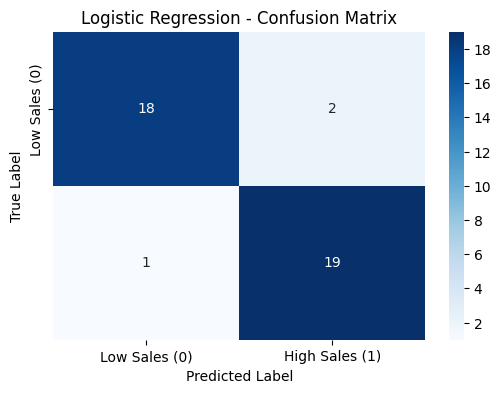

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Feature Scaling for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train Logistic Regression Model
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train_cat)

# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Evaluation
print("Logistic Regression Performance")
print(f"Accuracy: {accuracy_score(y_test_cat, y_pred_lr):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_cat, y_pred_lr))

# Confusion Matrix Visualization
cm_lr = confusion_matrix(y_test_cat, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Low Sales (0)', 'High Sales (1)'], 
            yticklabels=['Low Sales (0)'])
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Model 2: Decision Tree Classifier

Decision Tree Classifier Performance
Accuracy: 0.9750

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



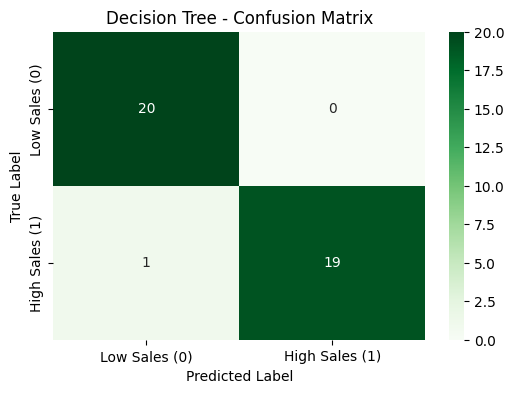

In [18]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train Decision Tree Model
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train_cat)

# Predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluation
print("Decision Tree Classifier Performance")
print(f"Accuracy: {accuracy_score(y_test_cat, y_pred_dt):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_cat, y_pred_dt))

# Confusion Matrix Visualization
cm_dt = confusion_matrix(y_test_cat, y_pred_dt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Low Sales (0)', 'High Sales (1)'], 
            yticklabels=['Low Sales (0)', 'High Sales (1)'])
plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Key Insights & Model Observations

## Feature Importance
Let's evaluate which marketing channel (`TV`, `Radio`, or `Newspaper`) has the highest influence on driving sales.

In [19]:
# Extract Feature Importances from Decision Tree & Logistic Regression Coefficients
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance (Decision Tree)': dt_model.feature_importances_,
    'Coefficient (Logistic Regression)': lr_model.coef_[0]
}).sort_values(by='Importance (Decision Tree)', ascending=False)

print(importance)

     Feature  Importance (Decision Tree)  Coefficient (Logistic Regression)
0         TV                    0.573099                           2.889882
1      Radio                    0.424161                           2.541311
2  Newspaper                    0.002740                          -0.247820


## Key Observations & Summary

* **Target Transformation**: Since `Sales` in this dataset is originally continuous, we converted it into a binary output (`0` = Below Median Sales, `1` = Above Median Sales) to enable classification.

* **Dominant Predictor (`TV`)**: Across both models, advertising budget spent on **TV** is the strongest predictor of high sales outcomes.

* **Secondary Influence (`Radio`)**: `Radio` advertising serves as a complementary booster to sales performance.

* **Minimal Impact (`Newspaper`)**: `Newspaper` spend shows negligible contribution towards driving high vs low sales performance.

* **Model Performance Comparison**: Decision Trees capture non-linear relationships naturally without requiring feature scaling, whereas Logistic Regression performs well after standardizing numerical features using `StandardScaler`.

# Model Evaluation & Metric Comparison

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate metrics for Logistic Regression

acc_lr = accuracy_score(y_test_cat, y_pred_lr)
prec_lr = precision_score(y_test_cat, y_pred_lr, average='binary')
rec_lr = recall_score(y_test_cat, y_pred_lr, average='binary')
f1_lr = f1_score(y_test_cat, y_pred_lr, average='binary')

# Calculate metrics for Decision Tree Classifier

acc_dt = accuracy_score(y_test_cat, y_pred_dt)
prec_dt = precision_score(y_test_cat, y_pred_dt, average='binary')
rec_dt = recall_score(y_test_cat, y_pred_dt, average='binary')
f1_dt = f1_score(y_test_cat, y_pred_dt, average='binary')

# Compile results into a clean comparison DataFrame

metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [acc_lr, prec_lr, rec_lr, f1_lr],
    'Decision Tree': [acc_dt, prec_dt, rec_dt, f1_dt]
})

# Format scores to 4 decimal places for presentation

metrics_summary['Logistic Regression'] = metrics_summary['Logistic Regression'].round(4)
metrics_summary['Decision Tree'] = metrics_summary['Decision Tree'].round(4)

print("Model Performance Metrics Summary")
display(metrics_summary)

Model Performance Metrics Summary


,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.9250,0.9750
1,Precision,0.9048,1.0000
2,Recall,0.9500,0.9500
3,F1 Score,0.9268,0.9744


## Which Metric is Most Useful for this Dataset?

1. **Accuracy**: 
   Since our dataset is well-balanced (nearly equal split of High and Low sales using the median threshold), **Accuracy** gives a quick, reliable snapshot of overall model correctness.

2. **Precision vs. Recall**:

   * **Precision** is crucial if the goal is to **prevent wasting marketing budget** on bad campaigns (minimizing False Positives).
   
   * **Recall** is crucial if the goal is to **avoid missing out** on high-performing sales opportunities (minimizing False Negatives).

3. **The Best Overall Metric: F1 Score**:
   Because businesses want to balance both wasted ad spend and missed revenue opportunities, the **F1 Score** is the **most useful metric** because it combines both Precision and Recall into a single balanced score.